# Setup & Load Untouched Raw Data (Kaggle CSV)

In [1]:
import glob
import os
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score, average_precision_score, f1_score,
    classification_report, precision_recall_curve
)
from lightgbm import LGBMClassifier
import shap

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

# Anchor working directory to day-15-lead-scoring/src
PROJECT_SRC = r"C:\Users\adjis\github\100-days-real-world-ml\day-15-lead-scoring\src"
if os.path.exists(PROJECT_SRC):
    os.chdir(PROJECT_SRC)
os.makedirs("outputs", exist_ok=True)

matches = glob.glob("../data/raw/**/Leads.csv", recursive=True)
CSV_PATH = matches[0] if matches else "../data/raw/Leads.csv"

df_raw = pd.read_csv(CSV_PATH)
print(f"Working directory : {os.getcwd()}")
print(f"Raw Dataset Shape : {df_raw.shape[0]:,} rows, {df_raw.shape[1]} columns")
df_raw.head()

C:\Users\adjis\anaconda3\envs\100-days-real-world-ml\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Working directory : C:\Users\adjis\github\100-days-real-world-ml\day-15-lead-scoring\src
Raw Dataset Shape : 9,240 rows, 37 columns


,Prospect ID,Lead Number,Lead Origin,Lead Source,Do Not Email,Do Not Call,Converted,TotalVisits,Total Time Spent on Website,Page Views Per Visit,...,Get updates on DM Content,Lead Profile,City,Asymmetrique Activity Index,Asymmetrique Profile Index,Asymmetrique Activity Score,Asymmetrique Profile Score,I agree to pay the amount through cheque,A free copy of Mastering The Interview,Last Notable Activity
0,7927b2df-8bba-4d29-b9a2-b6e0beafe620,660737,API,Olark Chat,No,No,0,0.0,0,0.0,...,No,Select,Select,02.Medium,02.Medium,15.0,15.0,No,No,Modified
1,2a272436-5132-4136-86fa-dcc88c88f482,660728,API,Organic Search,No,No,0,5.0,674,2.5,...,No,Select,Select,02.Medium,02.Medium,15.0,15.0,No,No,Email Opened
2,8cc8c611-a219-4f35-ad23-fdfd2656bd8a,660727,Landing Page Submission,Direct Traffic,No,No,1,2.0,1532,2.0,...,No,Potential Lead,Mumbai,02.Medium,01.High,14.0,20.0,No,Yes,Email Opened
3,0cc2df48-7cf4-4e39-9de9-19797f9b38cc,660719,Landing Page Submission,Direct Traffic,No,No,0,1.0,305,1.0,...,No,Select,Mumbai,02.Medium,01.High,13.0,17.0,No,No,Modified
4,3256f628-e534-4826-9d63-4a8b88782852,660681,Landing Page Submission,Google,No,No,1,2.0,1428,1.0,...,No,Select,Mumbai,02.Medium,01.High,15.0,18.0,No,No,Modified


# EDA 1: Schema, 'Select' Hidden Missingness, Zero-Variance & Case-Mismatch Audit

In [2]:
print(f"Exact Duplicate Rows : {df_raw.duplicated().sum()}")
print(f"Unique Prospect IDs  : {df_raw['Prospect ID'].nunique():,}")

audit_records = []
for col in df_raw.columns:
    std_null = df_raw[col].isnull().sum()
    select_cnt = (df_raw[col] == "Select").sum() if df_raw[col].dtype == "object" else 0
    total_effective_null = std_null + select_cnt
    n_uniq = df_raw[col].nunique(dropna=True)

    flag = "OK"
    if n_uniq <= 1:
        flag = "ZERO VARIANCE (Drop)"
    elif total_effective_null / len(df_raw) > 0.35:
        flag = "HIGH MISSINGNESS (>35%)"

    audit_records.append({
        "Column": col,
        "Dtype": str(df_raw[col].dtype),
        "Std_Nulls": std_null,
        "Hidden_'Select'": select_cnt,
        "Effective_Null_Pct (%)": round((total_effective_null / len(df_raw)) * 100, 2),
        "Unique_Values": n_uniq,
        "Audit_Flag": flag,
    })

audit_df = pd.DataFrame(audit_records)
display(audit_df[audit_df["Audit_Flag"] != "OK"].sort_values(by="Effective_Null_Pct (%)", ascending=False))

# Prove case-sensitivity bug in Lead Source ('Google' vs 'google')
print("\n[CASE MISMATCH CHECK] Top values in 'Lead Source':")
display(df_raw["Lead Source"].value_counts().head(8).to_frame("Count"))

Exact Duplicate Rows : 0
Unique Prospect IDs  : 9,240


,Column,Dtype,Std_Nulls,Hidden_'Select',Effective_Null_Pct (%),Unique_Values,Audit_Flag
25,Lead Quality,str,4767,0,51.59,5,HIGH MISSINGNESS (>35%)
30,Asymmetrique Activity Index,str,4218,0,45.65,3,HIGH MISSINGNESS (>35%)
32,Asymmetrique Activity Score,float64,4218,0,45.65,12,HIGH MISSINGNESS (>35%)
33,Asymmetrique Profile Score,float64,4218,0,45.65,10,HIGH MISSINGNESS (>35%)
31,Asymmetrique Profile Index,str,4218,0,45.65,3,HIGH MISSINGNESS (>35%)
24,Tags,str,3353,0,36.29,26,HIGH MISSINGNESS (>35%)
17,Magazine,str,0,0,0.00,1,ZERO VARIANCE (Drop)
23,Receive More Updates About Our Courses,str,0,0,0.00,1,ZERO VARIANCE (Drop)
26,Update me on Supply Chain Content,str,0,0,0.00,1,ZERO VARIANCE (Drop)
27,Get updates on DM Content,str,0,0,0.00,1,ZERO VARIANCE (Drop)



[CASE MISMATCH CHECK] Top values in 'Lead Source':


,Count
Lead Source,
Google,2868
Direct Traffic,2543
Olark Chat,1755
Organic Search,1154
Reference,534
Welingak Website,142
Referral Sites,125
Facebook,55


# EDA 2: Target Distribution, Website Engagement, Outliers & Leakage Proof

Target Variable ('Converted') Distribution:


,Count,Percentage (%)
Converted,,
0,5679,61.46
1,3561,38.54


,count,mean,std,50%,99%,max
TotalVisits,9103.0,3.45,4.85,3.0,17.00,251.0
Total Time Spent on Website,9240.0,487.70,548.02,248.0,1840.61,2272.0
Page Views Per Visit,9103.0,2.36,2.16,2.0,9.00,55.0


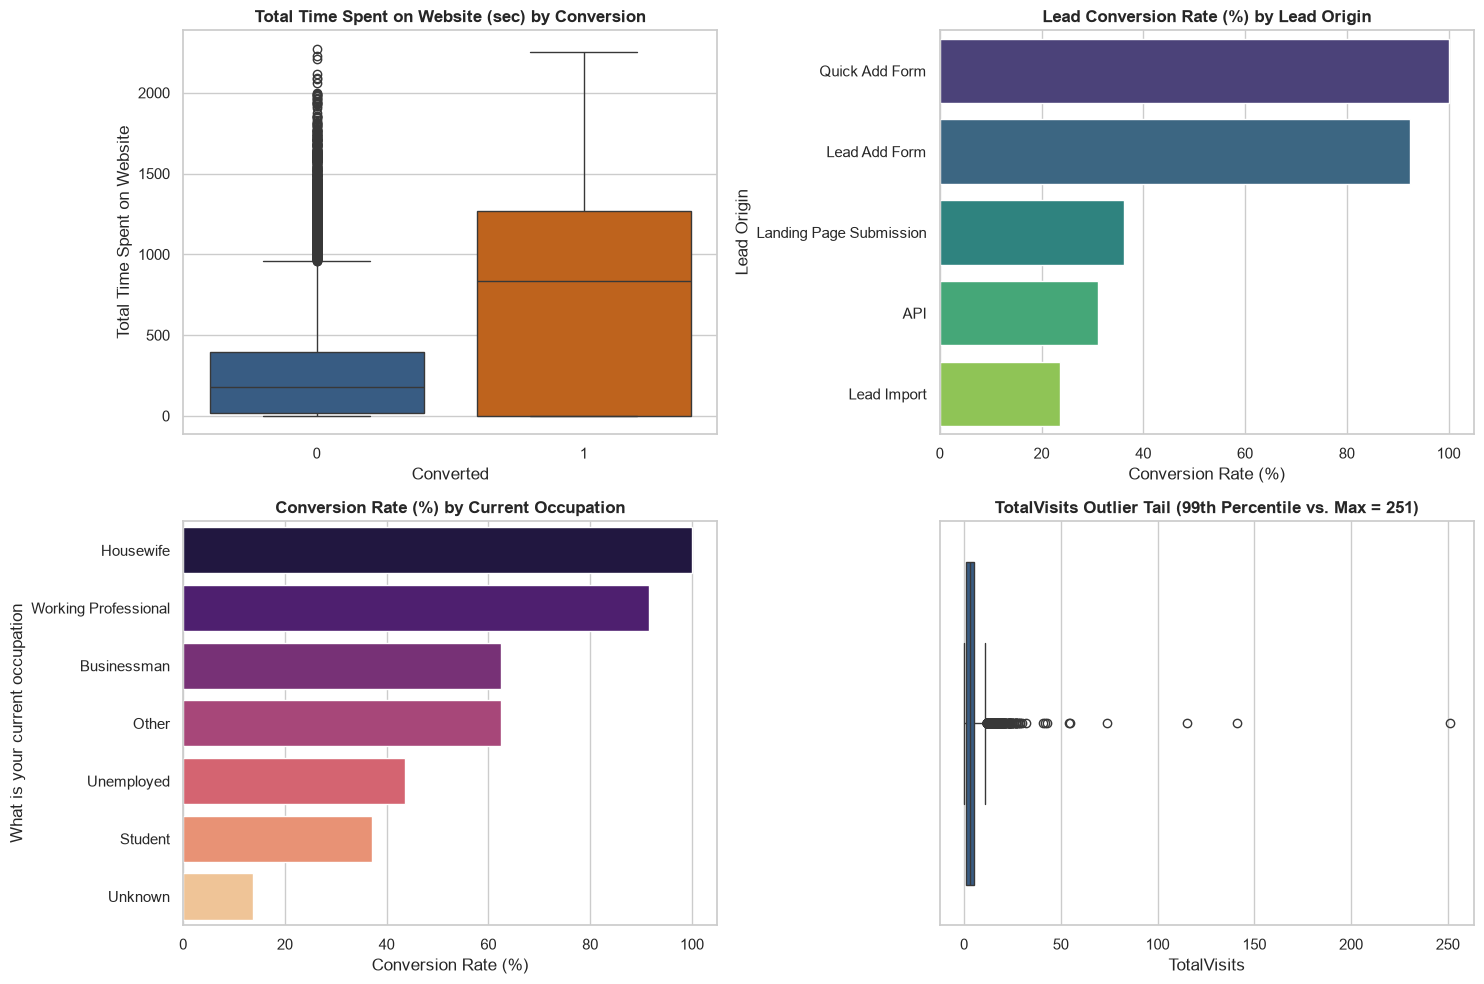

In [3]:
print("Target Variable ('Converted') Distribution:")
display(pd.DataFrame({
    "Count": df_raw["Converted"].value_counts(),
    "Percentage (%)": (df_raw["Converted"].value_counts(normalize=True) * 100).round(2)
}))

# Check IQR & 99th percentile outliers on numerical engagement columns
num_audit = ["TotalVisits", "Total Time Spent on Website", "Page Views Per Visit"]
desc = df_raw[num_audit].describe(percentiles=[0.25, 0.5, 0.75, 0.99]).T[["count", "mean", "std", "50%", "99%", "max"]]
display(desc.round(2))

# Visual EDA Dashboard
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Plot 1: Time Spent on Website by Conversion
sns.boxplot(data=df_raw, x="Converted", y="Total Time Spent on Website", palette=["#2b5c8f", "#d95f02"], ax=axes[0, 0])
axes[0, 0].set_title("Total Time Spent on Website (sec) by Conversion", fontweight="bold")

# Plot 2: Conversion Rate by Lead Origin
origin_conv = df_raw.groupby("Lead Origin")["Converted"].mean().sort_values(ascending=False) * 100
sns.barplot(x=origin_conv.values, y=origin_conv.index, palette="viridis", ax=axes[0, 1])
axes[0, 1].set_title("Lead Conversion Rate (%) by Lead Origin", fontweight="bold")
axes[0, 1].set_xlabel("Conversion Rate (%)")

# Plot 3: Conversion Rate by Current Occupation (Replacing 'Select' for preview)
occ_clean = df_raw["What is your current occupation"].replace({"Select": "Unknown"}).fillna("Unknown")
occ_conv = df_raw.groupby(occ_clean)["Converted"].mean().sort_values(ascending=False) * 100
sns.barplot(x=occ_conv.values, y=occ_conv.index, palette="magma", ax=axes[1, 0])
axes[1, 0].set_title("Conversion Rate (%) by Current Occupation", fontweight="bold")
axes[1, 0].set_xlabel("Conversion Rate (%)")

# Plot 4: TotalVisits Outlier Spread (Showing extreme bot/crawler tail)
sns.boxplot(x=df_raw["TotalVisits"].dropna(), color="#2b5c8f", ax=axes[1, 1])
axes[1, 1].set_title("TotalVisits Outlier Tail (99th Percentile vs. Max = 251)", fontweight="bold")

plt.tight_layout()
plt.savefig("outputs/eda_lead_scoring.png", dpi=150)
plt.show()

# Evidence-Based Data Cleaning

In [4]:
"""
Cleaning Rules Driven by EDA Findings:
1. Replace literal "'Select'" web-form defaults with np.nan so missingness is handled explicitly.
2. Drop unique identifiers ('Prospect ID', 'Lead Number') and all zero-variance single-category columns.
3. Drop post-call sales-team leakage columns ('Tags', 'Lead Quality', 'Last Notable Activity',
   and 'Asymmetrique*' sales-scored indices) so the model can score brand-new inbound leads.
4. Fix case mismatch in 'Lead Source' ('google' -> 'Google') and fill missing informative
   categorical columns with 'Unknown' rather than dropping ~35% of leads.
"""
df_clean = df_raw.replace("Select", np.nan).copy()

# 1. Drop IDs, zero-variance constants, and post-call sales leakage columns
zero_var_cols = [c for c in df_clean.columns if df_clean[c].nunique(dropna=True) <= 1]
leakage_cols = [
    "Tags", "Lead Quality", "Last Notable Activity",
    "Asymmetrique Activity Index", "Asymmetrique Profile Index",
    "Asymmetrique Activity Score", "Asymmetrique Profile Score"
]
id_cols = ["Prospect ID", "Lead Number"]

cols_to_drop = list(set(zero_var_cols + leakage_cols + id_cols))
df_clean.drop(columns=[c for c in cols_to_drop if c in df_clean.columns], inplace=True)

# 2. Fix case sensitivity & standardize binary Yes/No columns
df_clean["Lead Source"] = df_clean["Lead Source"].replace({"google": "Google"})
for bin_col in ["Do Not Email", "Do Not Call", "A free copy of Mastering The Interview"]:
    if bin_col in df_clean.columns:
        df_clean[bin_col] = (df_clean[bin_col] == "Yes").astype(int)

# 3. Fill informative missing categoricals as 'Unknown'
cat_fill_cols = [
    "Specialization", "How did you hear about X Education",
    "What is your current occupation", "What matters most to you in choosing a course",
    "Lead Profile", "Country", "City"
]
for c in cat_fill_cols:
    if c in df_clean.columns:
        df_clean[c] = df_clean[c].fillna("Unknown")

print(f"Dropped {len(cols_to_drop)} non-informative/leakage columns.")
print(f"Cleaned Inbound-Ready Dataset Shape: {df_clean.shape[0]:,} rows, {df_clean.shape[1]} columns | Conversion Rate: {df_clean['Converted'].mean():.2%}")

Dropped 14 non-informative/leakage columns.
Cleaned Inbound-Ready Dataset Shape: 9,240 rows, 23 columns | Conversion Rate: 38.54%


# CRM Engagement Feature Engineering & Leak-Free Preprocessing

In [5]:
df_feat = df_clean.copy()

# 1. Website engagement intensity & average duration per visit
df_feat["avg_time_per_visit"] = df_feat["Total Time Spent on Website"] / (df_feat["TotalVisits"].fillna(0) + 1.0)
df_feat["is_zero_website_engagement"] = (df_feat["Total Time Spent on Website"] == 0).astype(int)

# 2. Profile completeness score (counts how many optional web-form fields the lead filled)
profile_cols = ["Specialization", "What is your current occupation", "City", "Country"]
df_feat["form_fields_completed"] = sum((df_feat[c] != "Unknown").astype(int) for c in profile_cols)

# 3. High-intent occupation & origin flags from EDA Cell 3
df_feat["is_working_professional"] = (df_feat["What is your current occupation"] == "Working Professional").astype(int)

X = df_feat.drop(columns=["Converted"])
y = df_feat["Converted"].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Leak-free 99th-percentile capping for extreme bot outliers in TotalVisits & Page Views Per Visit
for col in ["TotalVisits", "Page Views Per Visit"]:
    cap_val = X_train[col].quantile(0.99)
    X_train[col] = X_train[col].clip(upper=cap_val)
    X_test[col] = X_test[col].clip(upper=cap_val)

# Consolidate rare categories (< 1.5% in X_train) strictly inside training fold
cat_cols = X_train.select_dtypes(include=["object"]).columns.tolist()
for c in cat_cols:
    freq = X_train[c].value_counts(normalize=True)
    keep = freq[freq >= 0.015].index.tolist()
    X_train[c] = X_train[c].where(X_train[c].isin(keep), "Other")
    X_test[c] = X_test[c].where(X_test[c].isin(keep), "Other")

num_cols = [c for c in X_train.columns if c not in cat_cols]

preprocessor = ColumnTransformer(transformers=[
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]), num_cols),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ]), cat_cols),
])

print(f"Train Set: {X_train.shape} | Test Set: {X_test.shape}")

Train Set: (7392, 26) | Test Set: (1848, 26)


# Model Benchmarking (Logistic Regression vs. LightGBM) & 0–100 Lead Score Calibration

In [6]:
def find_optimal_f1_threshold(y_true, y_probs):
    precisions, recalls, thresholds = precision_recall_curve(y_true, y_probs)
    f1_scores = (2 * precisions * recalls) / (precisions + recalls + 1e-8)
    best_idx = np.argmax(f1_scores[:-1])
    return float(thresholds[best_idx])

def top_k_conversion_rate(y_true, y_probs, top_frac=0.30):
    """Conversion rate among the top K% highest-scored 'Hot Leads'."""
    n_top = int(len(y_true) * top_frac)
    top_idx = np.argsort(y_probs)[::-1][:n_top]
    return float(y_true[top_idx].mean()) * 100.0

models = {
    "Logistic Regression (Inbound Baseline)": Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(C=0.5, class_weight="balanced", max_iter=1000, random_state=42)),
    ]),
    "LightGBM (Inbound Lead Scoring Engine)": Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", LGBMClassifier(
            n_estimators=300,
            learning_rate=0.04,
            num_leaves=31,
            max_depth=6,
            subsample=0.8,
            colsample_bytree=0.8,
            random_state=42,
            verbose=-1,
        )),
    ]),
}

best_model, best_roc_auc = None, 0.0

for name, pipeline in models.items():
    pipeline.fit(X_train, y_train)
    y_probs = pipeline.predict_proba(X_test)[:, 1]
    opt_thresh = find_optimal_f1_threshold(y_test, y_probs)
    y_pred = (y_probs >= opt_thresh).astype(int)

    roc_auc = roc_auc_score(y_test, y_probs)
    pr_auc = average_precision_score(y_test, y_probs)
    hot_lead_conv = top_k_conversion_rate(y_test, y_probs, top_frac=0.30)

    print(f"\n---> {name}")
    print(f"ROC-AUC : {roc_auc:.4f} | PR-AUC : {pr_auc:.4f} | Top-30% Hot-Lead Conversion : {hot_lead_conv:.2f}% | Threshold : {opt_thresh:.4f}")
    print(classification_report(y_test, y_pred, target_names=["Cold/Lost (0)", "Converted (1)"]))

    if roc_auc > best_roc_auc:
        best_roc_auc = roc_auc
        best_model = pipeline

joblib.dump(best_model, "outputs/best_lead_scoring_model.joblib")


---> Logistic Regression (Inbound Baseline)
ROC-AUC : 0.8902 | PR-AUC : 0.8304 | Top-30% Hot-Lead Conversion : 81.59% | Threshold : 0.3625
               precision    recall  f1-score   support

Cold/Lost (0)       0.92      0.73      0.82      1136
Converted (1)       0.68      0.90      0.78       712

     accuracy                           0.80      1848
    macro avg       0.80      0.82      0.80      1848
 weighted avg       0.83      0.80      0.80      1848


---> LightGBM (Inbound Lead Scoring Engine)
ROC-AUC : 0.8997 | PR-AUC : 0.8550 | Top-30% Hot-Lead Conversion : 83.21% | Threshold : 0.3200
               precision    recall  f1-score   support

Cold/Lost (0)       0.92      0.77      0.84      1136
Converted (1)       0.71      0.89      0.79       712

     accuracy                           0.82      1848
    macro avg       0.81      0.83      0.81      1848
 weighted avg       0.84      0.82      0.82      1848



['outputs/best_lead_scoring_model.joblib']

# SHAP Explainability (What Makes a Hot Lead?)

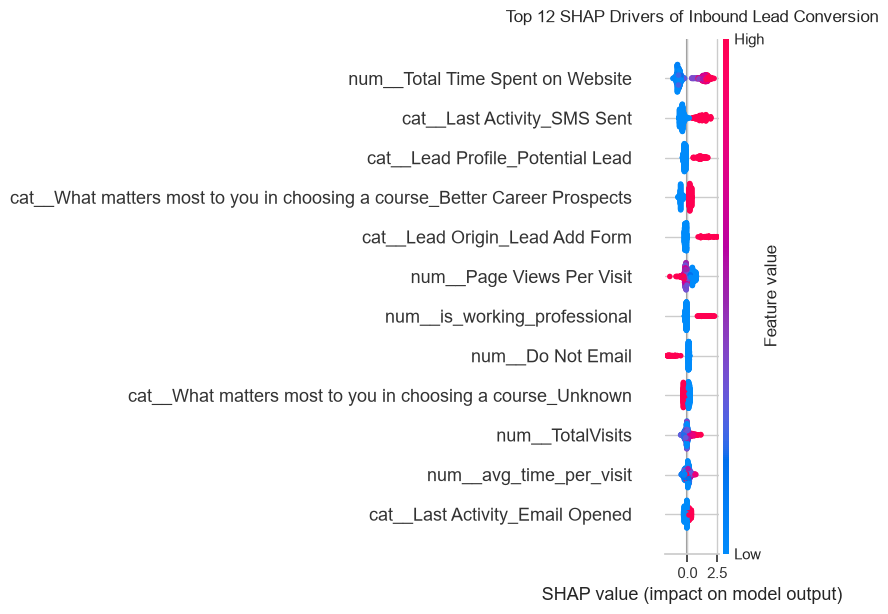

In [7]:
lgbm_pipe = models["LightGBM (Inbound Lead Scoring Engine)"]

X_test_sample = X_test.sample(min(800, len(X_test)), random_state=42)
X_test_transformed = lgbm_pipe.named_steps["preprocessor"].transform(X_test_sample)
feature_names = lgbm_pipe.named_steps["preprocessor"].get_feature_names_out()

explainer = shap.TreeExplainer(lgbm_pipe.named_steps["classifier"])
shap_values = explainer.shap_values(X_test_transformed)
shap_vals_to_plot = shap_values[1] if isinstance(shap_values, list) else shap_values

plt.figure(figsize=(10, 6))
shap.summary_plot(shap_vals_to_plot, X_test_transformed, feature_names=feature_names, show=False, max_display=12)
plt.title("Top 12 SHAP Drivers of Inbound Lead Conversion", fontsize=12, pad=12)
plt.tight_layout()
plt.savefig("outputs/shap_lead_scoring.png", dpi=150)
plt.show()

# 10-Decile Lead Score Calibration & Conversion Lift Table (0–100 Score)

In [8]:
lgbm_pipe = models["LightGBM (Inbound Lead Scoring Engine)"]
lead_probs = lgbm_pipe.predict_proba(X_test)[:, 1]

decile_df = pd.DataFrame({
    "Lead_Score_0_100": (lead_probs * 100).round(1),
    "Actual_Converted": y_test,
})

# Rank leads into 10 equal-sized buckets (Decile 1 = Top 10% Hottest Leads)
decile_df["Decile"] = pd.qcut(
    decile_df["Lead_Score_0_100"].rank(method="first", ascending=False),
    q=10,
    labels=[f"Decile {i}" for i in range(1, 11)],
)

decile_summary = (
    decile_df.groupby("Decile", observed=False)
    .agg(
        Leads_Count=("Actual_Converted", "count"),
        Conversions=("Actual_Converted", "sum"),
        Min_Score=("Lead_Score_0_100", "min"),
        Max_Score=("Lead_Score_0_100", "max"),
        Conversion_Rate_Pct=("Actual_Converted", lambda s: s.mean() * 100),
    )
    .reset_index()
)

decile_summary["Cumulative_Conversions_Captured_%"] = (
    decile_summary["Conversions"].cumsum() / decile_summary["Conversions"].sum() * 100
)

print("10-Decile Lead Scoring Performance (Decile 1 = Top 10% Hottest Leads):")
display(decile_summary.round(2))

10-Decile Lead Scoring Performance (Decile 1 = Top 10% Hottest Leads):


,Decile,Leads_Count,Conversions,Min_Score,Max_Score,Conversion_Rate_Pct,Cumulative_Conversions_Captured_%
0,Decile 1,185,178,95.6,99.8,96.22,25.00
1,Decile 2,185,155,81.8,95.6,83.78,46.77
2,Decile 3,185,128,65.6,81.8,69.19,64.75
3,Decile 4,184,100,46.3,65.5,54.35,78.79
4,Decile 5,185,81,29.1,46.2,43.78,90.17
5,Decile 6,185,33,11.5,28.9,17.84,94.80
6,Decile 7,184,15,6.7,11.4,8.15,96.91
7,Decile 8,185,8,3.2,6.6,4.32,98.03
8,Decile 9,185,7,1.2,3.2,3.78,99.02
9,Decile 10,185,7,0.1,1.2,3.78,100.00
